# EDA, Clean และ Data Prep: ปริมาณฝนรายเดือน (2020–2025)

ลำดับการทำงาน: โหลดข้อมูล → EDA/กราฟก่อน Clean → Clean → Data Prep → EDA/กราฟหลังเตรียมข้อมูล → Save CSV

## 1. โหลดข้อมูลต้นฉบับ

อ่านไฟล์ `NST_amphoe_monthly_rain_maxmin_2020_2025.csv` จาก `raw_data` และเลือกเฉพาะปี 2020–2025 ข้อมูลใน `raw_data` ยังเป็นข้อมูลก่อน Clean ใช้สำหรับ EDA รอบแรก

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

filename = 'NST_amphoe_monthly_rain_maxmin_2020_2025.csv'
root = next((path for path in [Path.cwd(), *Path.cwd().parents]
             if (path / 'raw_data' / filename).is_file()), None)
if root is None:
    raise FileNotFoundError(f'ไม่พบไฟล์ raw_data/{filename}')

source_path = root / 'raw_data' / filename
years = [2020, 2021, 2022, 2023, 2024, 2025]
all_data = pd.read_csv(source_path)
raw_data = all_data.loc[all_data['year'].isin(years)].copy()

print(f'ไฟล์ต้นทาง: {source_path}')
print(f'ข้อมูลทั้งหมด {len(all_data)} แถว | ข้อมูลปี {years}: {len(raw_data)} แถว')
display(raw_data.head())

ไฟล์ต้นทาง: c:\Users\sitti\OneDrive\Desktop\nahh ahhh ver nine edit - Copy\nahh ahhh\raw_data\NST_amphoe_monthly_rain_maxmin_2020_2025.csv
ข้อมูลทั้งหมด 1296 แถว | ข้อมูลปี [2020, 2021, 2022, 2023, 2024, 2025]: 1296 แถว


,province,amphoe,year,month,month_th,rain_total_mm,rain_daily_max_mm,rain_daily_min_mm
0,นครศรีธรรมราช,Bang Khan,2020.0,1,มกราคม,15.164923,11.209288,0.0
1,นครศรีธรรมราช,Bang Khan,2020.0,2,กุมภาพันธ์,20.254243,17.960007,0.0
2,นครศรีธรรมราช,Bang Khan,2020.0,3,มีนาคม,26.391159,8.903893,0.0
3,นครศรีธรรมราช,Bang Khan,2020.0,4,เมษายน,138.922249,26.490426,0.0
4,นครศรีธรรมราช,Bang Khan,2020.0,5,พฤษภาคม,317.944093,28.707084,0.0


## 2. EDA ก่อน Clean: ตรวจข้อมูลและแสดงกราฟ

สำรวจ `raw_data` ก่อนทำความสะอาด แสดงภาพรวมปริมาณฝนสะสมรายเดือนรวมทุกอำเภอ และปริมาณฝนสูงสุดรายวันเฉลี่ยรายเดือน

ขนาดข้อมูล: (1296, 8)
ค่าว่างต่อคอลัมน์:
 province             0
amphoe               0
year                 0
month                0
month_th             0
rain_total_mm        0
rain_daily_max_mm    0
rain_daily_min_mm    0
แถวซ้ำทั้งหมด: 0
จำนวนอำเภอต่อปี:
 year
2020.0    18
2021.0    18
2022.0    18
2023.0    18
2024.0    18
2025.0    18


,rain_total_mm,rain_daily_max_mm,rain_daily_min_mm
count,1296.00,1296.00,1296.00
mean,229.13,36.63,0.01
std,181.86,28.24,0.11
min,0.93,0.49,0.00
25%,97.28,19.29,0.00
50%,196.86,29.31,0.00
75%,299.91,45.04,0.00
max,1060.52,213.42,2.48


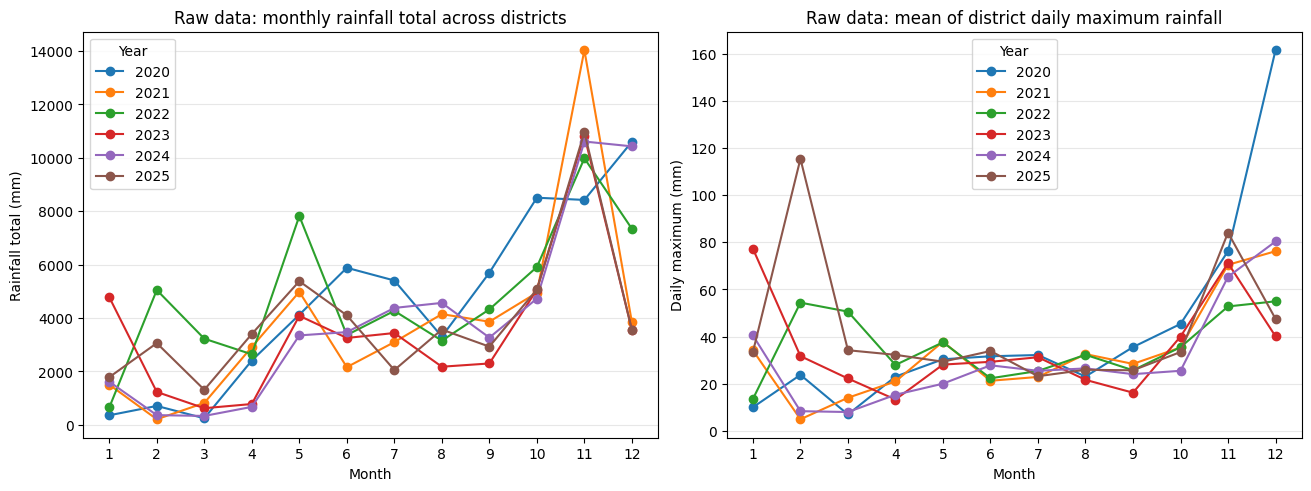

,year,month,rain_total_all_districts_mm,mean_daily_max_mm
0,2020.0,1,356.20,9.96
1,2020.0,2,705.79,23.72
2,2020.0,3,243.70,6.92
3,2020.0,4,2407.61,22.98
4,2020.0,5,4123.48,30.34
5,2020.0,6,5882.01,31.61
6,2020.0,7,5405.52,32.15
7,2020.0,8,3304.41,23.02
8,2020.0,9,5695.87,35.51
9,2020.0,10,8507.24,45.33


In [2]:
print('ขนาดข้อมูล:', raw_data.shape)
print('ค่าว่างต่อคอลัมน์:\n', raw_data.isna().sum().to_string())
print('แถวซ้ำทั้งหมด:', int(raw_data.duplicated().sum()))
print('จำนวนอำเภอต่อปี:\n', raw_data.groupby('year')['amphoe'].nunique().to_string())
display(raw_data[['rain_total_mm', 'rain_daily_max_mm', 'rain_daily_min_mm']].describe().round(2))

raw_monthly = raw_data.groupby(['year', 'month'], as_index=False).agg(
    rain_total_all_districts_mm=('rain_total_mm', 'sum'),
    mean_daily_max_mm=('rain_daily_max_mm', 'mean'),
)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)
for year in years:
    subset = raw_monthly.loc[raw_monthly['year'] == year]
    axes[0].plot(subset['month'], subset['rain_total_all_districts_mm'], marker='o', label=str(year))
    axes[1].plot(subset['month'], subset['mean_daily_max_mm'], marker='o', label=str(year))
axes[0].set(title='Raw data: monthly rainfall total across districts', xlabel='Month', ylabel='Rainfall total (mm)', xticks=range(1, 13))
axes[1].set(title='Raw data: mean of district daily maximum rainfall', xlabel='Month', ylabel='Daily maximum (mm)', xticks=range(1, 13))
for ax in axes:
    ax.grid(axis='y', alpha=.3)
    ax.legend(title='Year')
display(fig)
plt.close(fig)
display(raw_monthly.head(12).round(2))

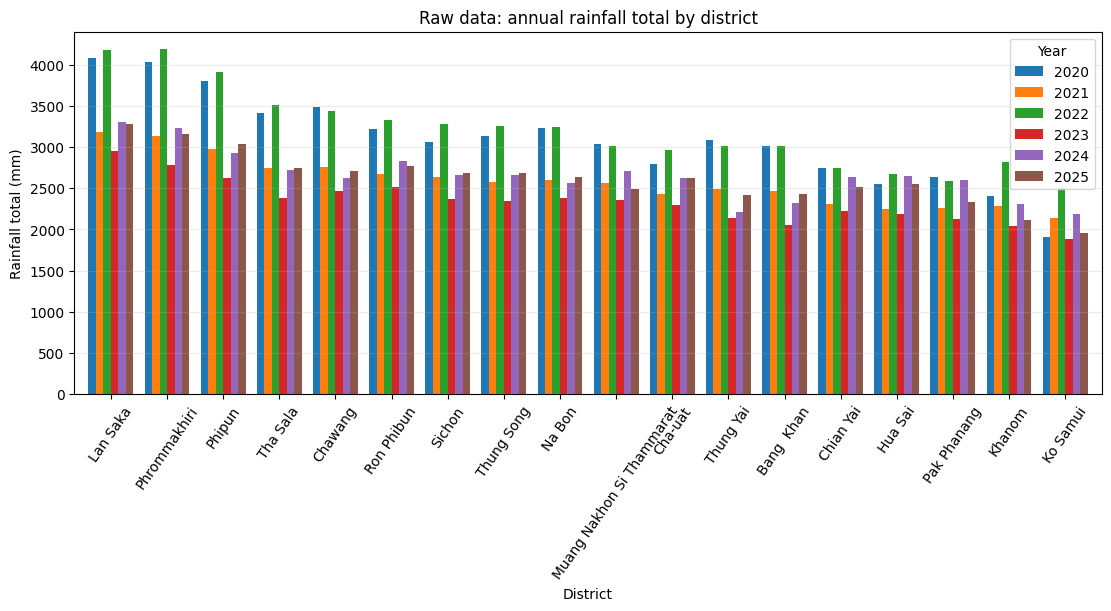

In [3]:
raw_district_year = raw_data.groupby(['amphoe', 'year'], as_index=False)['rain_total_mm'].sum()
raw_district_pivot = raw_district_year.pivot(index='amphoe', columns='year', values='rain_total_mm').reindex(columns=years)
raw_district_pivot = raw_district_pivot.loc[raw_district_pivot.mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(11, 6), constrained_layout=True)
raw_district_pivot.plot(kind='bar', ax=ax, width=.8)
ax.set(title='Raw data: annual rainfall total by district', xlabel='District', ylabel='Rainfall total (mm)')
ax.legend(title='Year')
ax.tick_params(axis='x', labelrotation=55)
ax.grid(axis='y', alpha=.25)
display(fig)
plt.close(fig)

## 3. Clean ข้อมูล

จัดช่องว่างในชื่อจังหวัดและอำเภอ แปลงคอลัมน์ตัวเลขให้เป็นชนิดตัวเลข ลบแถวซ้ำ และตัดแถวที่ขาดข้อมูลในคอลัมน์สำคัญ พร้อมตรวจว่าค่าฝนไม่ติดลบ ค่า 0 คงไว้ตามข้อมูลจริง

In [4]:
clean_data = raw_data.copy()
for column in ['province', 'amphoe', 'month_th']:
    clean_data[column] = clean_data[column].astype('string').str.strip()
clean_data['amphoe'] = clean_data['amphoe'].str.replace(r'\s+', ' ', regex=True)

numeric_columns = ['year', 'month', 'rain_total_mm', 'rain_daily_max_mm', 'rain_daily_min_mm']
for column in numeric_columns:
    clean_data[column] = pd.to_numeric(clean_data[column], errors='coerce')

rows_before = len(clean_data)
clean_data = clean_data.drop_duplicates().copy()
print(f'ลบแถวซ้ำ: {rows_before - len(clean_data)} แถว')

required_columns = ['province', 'amphoe', 'year', 'month', *numeric_columns[2:]]
missing_rows = int(clean_data[required_columns].isna().any(axis=1).sum())
if missing_rows:
    clean_data = clean_data.dropna(subset=required_columns).copy()
    print(f'ลบแถวที่ข้อมูลสำคัญขาดหาย/ไม่ใช่ตัวเลข: {missing_rows} แถว')
else:
    print('ไม่พบแถวที่ข้อมูลสำคัญขาดหายหรือไม่ใช่ตัวเลข')

valid_period = clean_data['year'].isin(years) & clean_data['month'].between(1, 12)
if not valid_period.all():
    print(f'ลบแถวปีหรือเดือนไม่ถูกต้อง: {int((~valid_period).sum())} แถว')
    clean_data = clean_data.loc[valid_period].copy()

rain_columns = ['rain_total_mm', 'rain_daily_max_mm', 'rain_daily_min_mm']
if (clean_data[rain_columns] < 0).any().any():
    raise ValueError('พบปริมาณฝนติดลบ กรุณาตรวจสอบข้อมูลต้นฉบับ')
if clean_data[['province', 'amphoe']].eq('').any().any():
    raise ValueError('พบชื่อจังหวัดหรืออำเภอว่าง กรุณาตรวจสอบข้อมูล')

print(f'Clean เสร็จ: {len(clean_data)} แถว | ยังคงค่าฝนศูนย์ไว้ตามข้อมูลต้นฉบับ')

ลบแถวซ้ำ: 0 แถว
ไม่พบแถวที่ข้อมูลสำคัญขาดหายหรือไม่ใช่ตัวเลข
Clean เสร็จ: 1296 แถว | ยังคงค่าฝนศูนย์ไว้ตามข้อมูลต้นฉบับ


## 4. Data Prep

เตรียมตารางวิเคราะห์แยกจาก Clean: แปลงปีและเดือนเป็นจำนวนเต็ม สร้างคอลัมน์วันที่เริ่มต้นของแต่ละเดือน เรียงข้อมูล และเลือกเฉพาะคอลัมน์ที่เกี่ยวข้อง

In [5]:
data_prep = clean_data.copy()
data_prep['year'] = data_prep['year'].astype('int64')
data_prep['month'] = data_prep['month'].astype('int64')
data_prep['date_month'] = pd.to_datetime(
    dict(year=data_prep['year'], month=data_prep['month'], day=1),
    errors='raise',
)
prepared_columns = [
    'province', 'amphoe', 'year', 'month', 'date_month', 'month_th',
    'rain_total_mm', 'rain_daily_max_mm', 'rain_daily_min_mm',
]
data_prep = data_prep[prepared_columns].sort_values(
    ['amphoe', 'year', 'month']
).reset_index(drop=True)

if not data_prep['year'].isin(years).all():
    raise ValueError('พบปีนอกช่วงที่ร้องขอ')
if data_prep.duplicated(['amphoe', 'year', 'month']).any():
    raise ValueError('พบข้อมูลซ้ำของอำเภอ ปี และเดือน')
if data_prep.isna().any().any():
    raise ValueError('พบค่าว่างในตาราง Data Prep')

print('ขนาดตาราง Data Prep:', data_prep.shape)
print('ปี:', sorted(data_prep['year'].unique().tolist()))
print('จำนวนอำเภอ:', data_prep['amphoe'].nunique())
display(data_prep.head(12))

ขนาดตาราง Data Prep: (1296, 9)
ปี: [2020, 2021, 2022, 2023, 2024, 2025]
จำนวนอำเภอ: 18


,province,amphoe,year,month,date_month,month_th,rain_total_mm,rain_daily_max_mm,rain_daily_min_mm
0,นครศรีธรรมราช,Bang Khan,2020,1,2020-01-01,มกราคม,15.164923,11.209288,0.000000
1,นครศรีธรรมราช,Bang Khan,2020,2,2020-02-01,กุมภาพันธ์,20.254243,17.960007,0.000000
2,นครศรีธรรมราช,Bang Khan,2020,3,2020-03-01,มีนาคม,26.391159,8.903893,0.000000
3,นครศรีธรรมราช,Bang Khan,2020,4,2020-04-01,เมษายน,138.922249,26.490426,0.000000
4,นครศรีธรรมราช,Bang Khan,2020,5,2020-05-01,พฤษภาคม,317.944093,28.707084,0.000000
5,นครศรีธรรมราช,Bang Khan,2020,6,2020-06-01,มิถุนายน,363.498166,30.485961,0.000000
6,นครศรีธรรมราช,Bang Khan,2020,7,2020-07-01,กรกฎาคม,326.831457,28.352902,0.027856
7,นครศรีธรรมราช,Bang Khan,2020,8,2020-08-01,สิงหาคม,226.483797,20.944811,0.000000
8,นครศรีธรรมราช,Bang Khan,2020,9,2020-09-01,กันยายน,391.651932,49.320551,0.000000
9,นครศรีธรรมราช,Bang Khan,2020,10,2020-10-01,ตุลาคม,417.343342,40.909811,0.000000


## 5. EDA หลัง Clean และ Data Prep

แสดงแนวโน้มปริมาณฝนจาก `data_prep` หลังผ่านขั้นตอน Clean และ Data Prep แล้ว ทั้งภาพรวมรายเดือนและยอดสะสมรายปีแยกอำเภอ

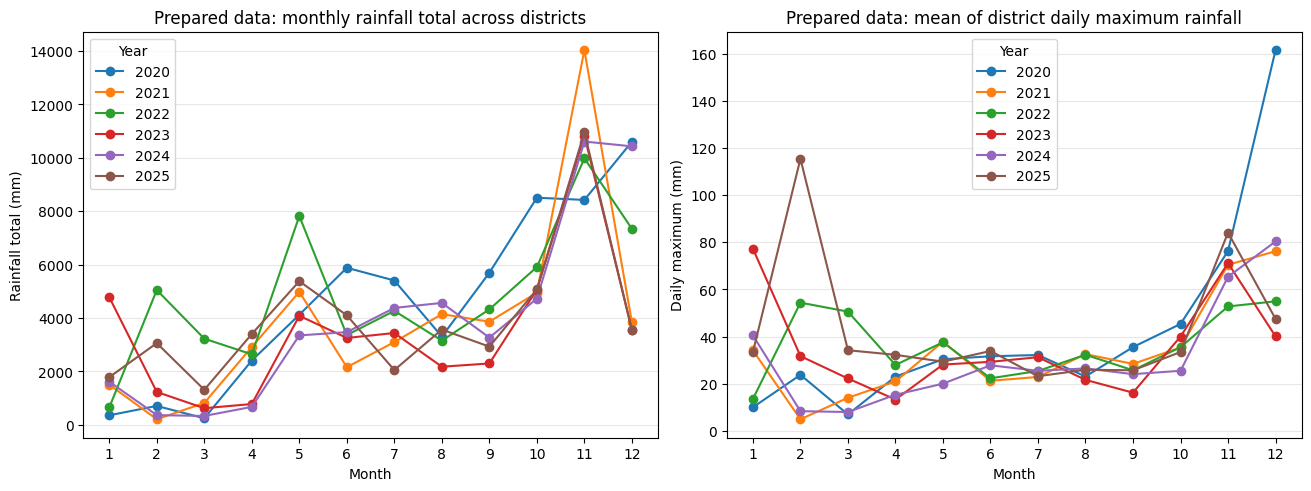

,year,month,rain_total_all_districts_mm,mean_daily_max_mm
0,2020,1,356.20,9.96
1,2020,2,705.79,23.72
2,2020,3,243.70,6.92
3,2020,4,2407.61,22.98
4,2020,5,4123.48,30.34
5,2020,6,5882.01,31.61
6,2020,7,5405.52,32.15
7,2020,8,3304.41,23.02
8,2020,9,5695.87,35.51
9,2020,10,8507.24,45.33


In [6]:
prepared_monthly = data_prep.groupby(['year', 'month'], as_index=False).agg(
    rain_total_all_districts_mm=('rain_total_mm', 'sum'),
    mean_daily_max_mm=('rain_daily_max_mm', 'mean'),
)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)
for year in years:
    subset = prepared_monthly.loc[prepared_monthly['year'] == year]
    axes[0].plot(subset['month'], subset['rain_total_all_districts_mm'], marker='o', label=str(year))
    axes[1].plot(subset['month'], subset['mean_daily_max_mm'], marker='o', label=str(year))
axes[0].set(title='Prepared data: monthly rainfall total across districts', xlabel='Month', ylabel='Rainfall total (mm)', xticks=range(1, 13))
axes[1].set(title='Prepared data: mean of district daily maximum rainfall', xlabel='Month', ylabel='Daily maximum (mm)', xticks=range(1, 13))
for ax in axes:
    ax.grid(axis='y', alpha=.3)
    ax.legend(title='Year')
display(fig)
plt.close(fig)
display(prepared_monthly.head(12).round(2))

## 6. Save CSV

บันทึก `data_prep` หลัง Clean และ Data Prep ลงใน `clean_data_set/` ขั้นตอน Save แยกเป็นเซลล์สุดท้าย

In [7]:
output_dir = root / 'clean_data_set'
output_dir.mkdir(parents=True, exist_ok=True)
csv_path = output_dir / 'NST_amphoe_monthly_rain_maxmin_2020_2025_clean.csv'
data_prep.to_csv(csv_path, index=False, encoding='utf-8-sig', float_format='%.6f', date_format='%Y-%m-%d')
print(f'บันทึก CSV แล้ว: {csv_path}')
print(f'{len(data_prep)} แถว | {data_prep["amphoe"].nunique()} อำเภอ | ปี {years}')

บันทึก CSV แล้ว: c:\Users\sitti\OneDrive\Desktop\nahh ahhh ver nine edit - Copy\nahh ahhh\clean_data_set\NST_amphoe_monthly_rain_maxmin_2020_2025_clean.csv
1296 แถว | 18 อำเภอ | ปี [2020, 2021, 2022, 2023, 2024, 2025]
